# Projet F14 – Taux hypothécaire et taux à 10 ans

**Établissement :** ENCG Settat – Filière Finance et Contrôle Interne – S7  
**Module :** Bases de Données et Data Science – Année 2026–2027  
**Étudiant :** Jawahir Abdelkebir  
**Sujet :** F14 – Taux hypothécaire et taux à 10 ans  

---

## 1. Cadrage du problème

### Contexte économique et financier
Les taux des prêts hypothécaires à 30 ans aux États-Unis sont étroitement liés aux conditions de financement de long terme. Le rendement des obligations du Trésor à 10 ans (benchmark de long terme) constitue une référence majeure pour le coût de refinancement des banques et donc pour les taux proposés aux emprunteurs.

### Problématique
> Dans quelle mesure le rendement des obligations américaines à 10 ans permet-il d’expliquer et de prévoir l’évolution du taux hypothécaire américain à 30 ans ?

### Objectif mesurable
Construire un modèle de **régression linéaire simple** estimant le taux hypothécaire à 30 ans à partir du rendement à 10 ans, et le comparer à une référence naïve (moyenne d’entraînement).

| Élément | Description |
|---------|-------------|
| Variable cible | `Mortgage_30Y` (MORTGAGE30US) |
| Variable explicative | `Treasury_10Y` (moyenne hebdomadaire de DGS10) |
| Tâche | Régression supervisée |
| Métrique principale | RMSE |
| Algorithme principal | Régression linéaire simple |


In [31]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Tentative d'import scikit-learn (fallback numpy si indisponible)
try:
    from sklearn.linear_model import LinearRegression, Ridge
    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
    HAS_SKLEARN = True
except ImportError:
    HAS_SKLEARN = False
    print("scikit-learn non disponible – utilisation de numpy pour la régression linéaire")

# Graine pour reproductibilité
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Chemins relatifs
ROOT = Path('..')
DATA_RAW = ROOT / 'data' / 'raw'
DATA = ROOT / 'data'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
print('Environnement prêt. HAS_SKLEARN =', HAS_SKLEARN)


Environnement prêt. HAS_SKLEARN = True


## 2. Compréhension et chargement des données

### Sources
- **MORTGAGE30US** : 30-Year Fixed Rate Mortgage Average (Freddie Mac via FRED) – hebdomadaire
- **DGS10** : Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity – quotidienne

URL : https://fred.stlouisfed.org/  
Date de consultation : novembre 2026  


In [32]:
# Chargement des fichiers directement depuis FRED pour éviter le FileNotFoundError
import os

# S'assurer que les dossiers de destination existent
DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

mort_path = DATA_RAW / 'MORTGAGE30US.csv'
dgs_path = DATA_RAW / 'DGS10.csv'

# Téléchargement si non présents localement
if not mort_path.exists():
    print("Téléchargement de MORTGAGE30US depuis FRED...")
    mort_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MORTGAGE30US"
    mort_df = pd.read_csv(mort_url)
    mort_df.to_csv(mort_path, index=False)

if not dgs_path.exists():
    print("Téléchargement de DGS10 depuis FRED...")
    dgs_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    dgs_df = pd.read_csv(dgs_url)
    dgs_df.to_csv(dgs_path, index=False)

# Chargement des fichiers bruts
mort = pd.read_csv(mort_path, parse_dates=['observation_date'], na_values=['.'])
dgs = pd.read_csv(dgs_path, parse_dates=['observation_date'], na_values=['.'])

mort = mort.rename(columns={'observation_date': 'date', 'MORTGAGE30US': 'Mortgage_30Y'})
dgs = dgs.rename(columns={'observation_date': 'date', 'DGS10': 'DGS10'})

mort = mort.dropna(subset=['Mortgage_30Y']).sort_values('date').reset_index(drop=True)
dgs = dgs.dropna(subset=['DGS10']).sort_values('date').reset_index(drop=True)

print('MORTGAGE30US :', mort.shape, '| période :', mort['date'].min().date(), '→', mort['date'].max().date())
print('DGS10        :', dgs.shape, '| période :', dgs['date'].min().date(), '→', dgs['date'].max().date())
print()
print('Aperçu MORTGAGE30US :')
display(mort.head(3))
print('Aperçu DGS10 :')
display(dgs.head(3))

MORTGAGE30US : (2903, 2) | période : 1971-04-02 → 2026-11-12
DGS10        : (16202, 2) | période : 1962-01-02 → 2026-11-13

Aperçu MORTGAGE30US :


,date,Mortgage_30Y
0,1971-04-02,7.33
1,1971-04-09,7.31
2,1971-04-16,7.31


Aperçu DGS10 :


,date,DGS10
0,1962-01-02,4.06
1,1962-01-03,4.03
2,1962-01-04,3.99


### Alignement des fréquences (anti-fuite)

Pour chaque date de référence du taux hypothécaire, on calcule la moyenne du DGS10 en n’utilisant **que les observations déjà disponibles à cette date** (date_DGS10 ≤ date_mortgage).


In [33]:
# Méthode d'alignement : moyenne des observations DGS10 de la semaine se terminant à la date du mortgage
# (jours ouvrés entre date-6 et date inclus)

def weekly_mean_up_to(dgs_df, ref_date):
    start = ref_date - pd.Timedelta(days=6)
    mask = (dgs_df['date'] >= start) & (dgs_df['date'] <= ref_date)
    vals = dgs_df.loc[mask, 'DGS10']
    if len(vals) == 0:
        # fallback : dernière valeur disponible <= ref_date
        past = dgs_df.loc[dgs_df['date'] <= ref_date, 'DGS10']
        return past.iloc[-1] if len(past) else np.nan
    return vals.mean()

# Calcul (peut prendre quelques secondes)
treasury_weekly = []
for d in mort['date']:
    treasury_weekly.append(weekly_mean_up_to(dgs, d))

df = mort.copy()
df['Treasury_10Y'] = treasury_weekly
df['Mortgage_Spread'] = df['Mortgage_30Y'] - df['Treasury_10Y']
df['Treasury_10Y_Lag1'] = df['Treasury_10Y'].shift(1)

df = df.dropna(subset=['Treasury_10Y']).reset_index(drop=True)
print('Dataset aligné :', df.shape)
print('Période :', df['date'].min().date(), '→', df['date'].max().date())
print('Valeurs manquantes restantes :')
print(df.isnull().sum())
display(df.head())
display(df.tail())


Dataset aligné : (2903, 5)
Période : 1971-04-02 → 2026-11-12
Valeurs manquantes restantes :
date                 0
Mortgage_30Y         0
Treasury_10Y         0
Mortgage_Spread      0
Treasury_10Y_Lag1    1
dtype: int64


,date,Mortgage_30Y,Treasury_10Y,Mortgage_Spread,Treasury_10Y_Lag1
0,1971-04-02,7.33,5.5500,1.7800,NaN
1,1971-04-09,7.31,5.6075,1.7025,5.5500
2,1971-04-16,7.31,5.7680,1.5420,5.6075
3,1971-04-23,7.31,5.9840,1.3260,5.7680
4,1971-04-30,7.29,6.0280,1.2620,5.9840


,date,Mortgage_30Y,Treasury_10Y,Mortgage_Spread,Treasury_10Y_Lag1
2898,2026-10-15,7.40,5.185,2.215,5.272
2899,2026-10-22,7.32,5.090,2.230,5.185
2900,2026-10-29,7.24,5.004,2.236,5.090
2901,2026-11-05,7.18,4.908,2.272,5.004
2902,2026-11-12,7.11,4.955,2.155,4.908


### Dictionnaire des variables et statistiques descriptives


In [34]:
dict_vars = pd.DataFrame({
    'Variable': ['date', 'Mortgage_30Y', 'Treasury_10Y', 'Mortgage_Spread', 'Treasury_10Y_Lag1'],
    'Rôle': ['Index temporel', 'Cible', 'Explicative principale', 'Analyse exploratoire', 'Variante retardée (passé)'],
    'Type': ['datetime', 'float', 'float', 'float', 'float'],
    'Unité': ['date', '%', '%', 'points de %', '%'],
    'Description': [
        'Date de référence hebdomadaire du taux hypothécaire',
        'Taux moyen des crédits immobiliers à taux fixe 30 ans (US)',
        'Moyenne hebdomadaire du rendement Trésor 10 ans (sans fuite)',
        'Écart Mortgage – Treasury (prime de risque approximative)',
        'Valeur de Treasury_10Y de la semaine précédente'
    ]
})
display(dict_vars)

print('\nStatistiques descriptives :')
display(df[['Mortgage_30Y', 'Treasury_10Y', 'Mortgage_Spread']].describe().round(3))

corr = df[['Mortgage_30Y', 'Treasury_10Y']].corr().iloc[0, 1]
print(f'\nCorrélation de Pearson Mortgage_30Y / Treasury_10Y : {corr:.4f}')


,Variable,Rôle,Type,Unité,Description
0,date,Index temporel,datetime,date,Date de référence hebdomadaire du taux hypothé...
1,Mortgage_30Y,Cible,float,%,Taux moyen des crédits immobiliers à taux fixe...
2,Treasury_10Y,Explicative principale,float,%,Moyenne hebdomadaire du rendement Trésor 10 an...
3,Mortgage_Spread,Analyse exploratoire,float,points de %,Écart Mortgage – Treasury (prime de risque app...
4,Treasury_10Y_Lag1,Variante retardée (passé),float,%,Valeur de Treasury_10Y de la semaine précédente



Statistiques descriptives :


,Mortgage_30Y,Treasury_10Y,Mortgage_Spread
count,2903.000,2903.000,2903.000
mean,7.680,5.916,1.764
std,3.175,3.109,0.520
min,2.650,0.546,0.037
25%,5.535,3.610,1.444
50%,7.220,5.686,1.666
75%,9.210,7.826,1.988
max,18.630,15.682,5.346



Corrélation de Pearson Mortgage_30Y / Treasury_10Y : 0.9865


## 3. Analyse exploratoire (EDA)

### Graphique 1 – Évolution historique des deux taux


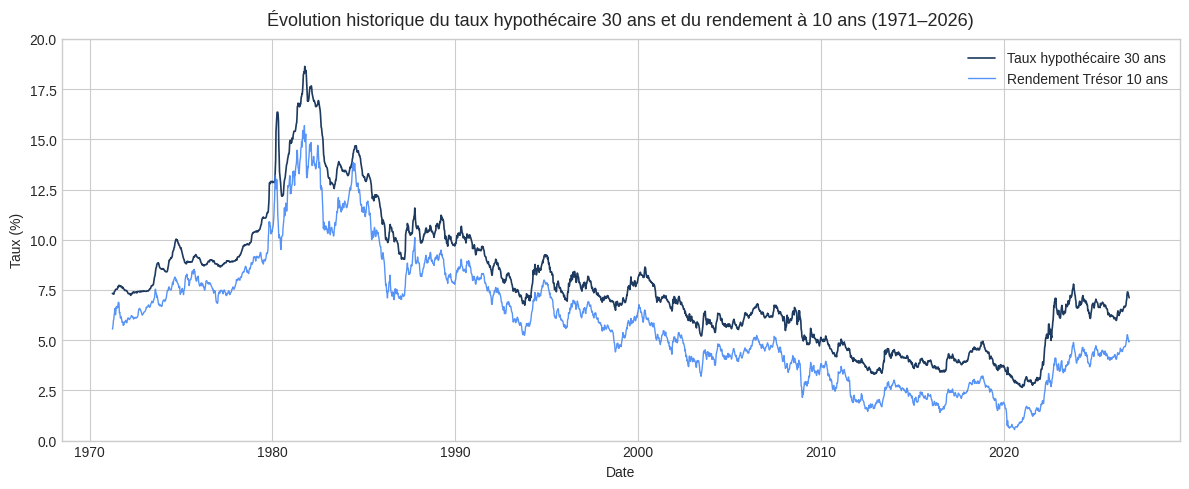

Interprétation : Les deux séries évoluent de façon très proche sur plus de 50 ans. Les pics des années 1980 (politique Volcker) et la remontée post-2021 sont clairement visibles. Le taux hypothécaire reste systématiquement au-dessus du taux à 10 ans (spread positif).


In [35]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['date'], df['Mortgage_30Y'], label='Taux hypothécaire 30 ans', color='#1e3a5f', linewidth=1.2)
ax.plot(df['date'], df['Treasury_10Y'], label='Rendement Trésor 10 ans', color='#3b82f6', linewidth=1.0, alpha=0.85)
ax.set_title('Évolution historique du taux hypothécaire 30 ans et du rendement à 10 ans (1971–2026)', fontsize=13, pad=10)
ax.set_xlabel('Date')
ax.set_ylabel('Taux (%)')
ax.legend(loc='upper right')
ax.set_ylim(0, 20)
plt.tight_layout()
plt.savefig(FIGURES / '01_evolution_historique.png', dpi=150, bbox_inches='tight')
plt.show()
print('Interprétation : Les deux séries évoluent de façon très proche sur plus de 50 ans. '
      'Les pics des années 1980 (politique Volcker) et la remontée post-2021 sont clairement visibles. '
      'Le taux hypothécaire reste systématiquement au-dessus du taux à 10 ans (spread positif).')


### Graphique 2 – Nuage de points et droite de tendance


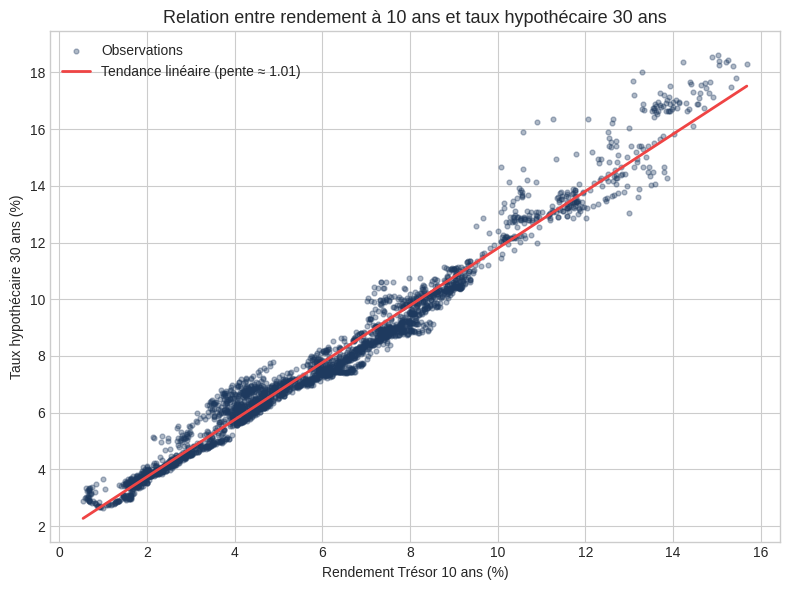

Interprétation : La relation apparaît fortement linéaire et positive. La pente proche de 1 indique qu’une variation du taux à 10 ans se transmet presque intégralement au taux hypothécaire, avec un écart (intercept) correspondant à la prime moyenne.


In [36]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df['Treasury_10Y'], df['Mortgage_30Y'], alpha=0.35, s=12, color='#1e3a5f', label='Observations')
# Droite de tendance
z = np.polyfit(df['Treasury_10Y'], df['Mortgage_30Y'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['Treasury_10Y'].min(), df['Treasury_10Y'].max(), 100)
ax.plot(x_line, p(x_line), color='#ef4444', linewidth=2, label=f'Tendance linéaire (pente ≈ {z[0]:.2f})')
ax.set_title('Relation entre rendement à 10 ans et taux hypothécaire 30 ans', fontsize=13)
ax.set_xlabel('Rendement Trésor 10 ans (%)')
ax.set_ylabel('Taux hypothécaire 30 ans (%)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / '02_nuage_points_tendance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Interprétation : La relation apparaît fortement linéaire et positive. '
      'La pente proche de 1 indique qu’une variation du taux à 10 ans se transmet presque intégralement au taux hypothécaire, '
      'avec un écart (intercept) correspondant à la prime moyenne.')


### Graphique 3 – Spread hypothécaire


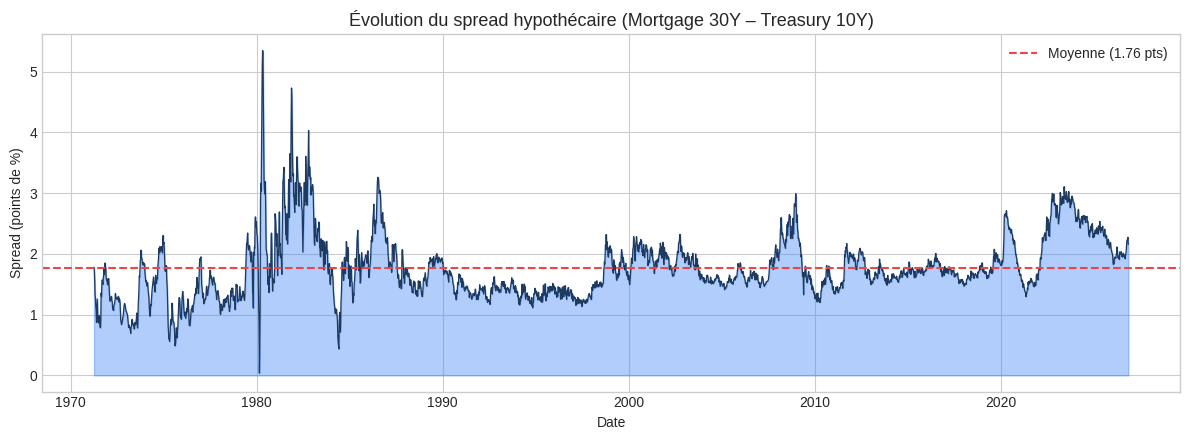

Interprétation : Le spread varie sensiblement selon les conditions de crédit et les périodes de stress (crise de 2008, pandémie, resserrement monétaire 2022–2023). Il n’est pas constant, ce qui limite un modèle purement linéaire à une seule variable.


In [37]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(df['date'], df['Mortgage_Spread'], alpha=0.4, color='#3b82f6')
ax.plot(df['date'], df['Mortgage_Spread'], color='#1e3a5f', linewidth=0.9)
ax.axhline(df['Mortgage_Spread'].mean(), color='#ef4444', linestyle='--', label=f'Moyenne ({df["Mortgage_Spread"].mean():.2f} pts)')
ax.set_title('Évolution du spread hypothécaire (Mortgage 30Y – Treasury 10Y)', fontsize=13)
ax.set_xlabel('Date')
ax.set_ylabel('Spread (points de %)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / '03_spread_hypothecaire.png', dpi=150, bbox_inches='tight')
plt.show()
print('Interprétation : Le spread varie sensiblement selon les conditions de crédit et les périodes de stress '
      '(crise de 2008, pandémie, resserrement monétaire 2022–2023). '
      'Il n’est pas constant, ce qui limite un modèle purement linéaire à une seule variable.')


## 4. Algorithme principal : régression linéaire simple

### Principe
La régression linéaire simple modélise la relation entre une variable cible continue $Y$ et une variable explicative $X$ par une droite :

$$
Y = \beta_0 + \beta_1 X + \varepsilon
$$

- $\beta_0$ : constante (intercept) – valeur moyenne de $Y$ lorsque $X = 0$
- $\beta_1$ : coefficient directeur – variation moyenne de $Y$ pour une hausse d’une unité de $X$
- $\varepsilon$ : terme d’erreur (résidu)

Les coefficients sont estimés par **moindres carrés ordinaires** (minimisation de $\sum \varepsilon_i^2$).

### Métriques
- **RMSE** : $\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$ – métrique principale
- **MAE** : $\frac{1}{n}\sum |y_i - \hat{y}_i|$
- **R²** : proportion de variance expliquée

### Hypothèses et limites
Linéarité, indépendance des erreurs, homoscédasticité, normalité approximative des résidus.  
En finance, ces hypothèses sont rarement parfaitement respectées (autocorrélation, régimes changeants).  
Avantage : interprétabilité et robustesse.  
Comparaison : la régression polynomiale capture une non-linéarité éventuelle ; Ridge régularise les coefficients.

### Schéma du protocole
Données brutes → Alignement anti-fuite → Découpage chronologique → Entraînement (estimation $\beta$) → Prédiction → Évaluation (RMSE / MAE / R²) vs référence naïve.


## 5. Entraînement, validation et test (découpage chronologique)


In [38]:
n = len(df)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train = df.iloc[:n_train].copy()
val = df.iloc[n_train:n_train + n_val].copy()
test = df.iloc[n_train + n_val:].copy()

print(f'Train : {len(train)} obs. | {train["date"].min().date()} → {train["date"].max().date()}')
print(f'Val   : {len(val)} obs. | {val["date"].min().date()} → {val["date"].max().date()}')
print(f'Test  : {len(test)} obs. | {test["date"].min().date()} → {test["date"].max().date()}')

X_train = train['Treasury_10Y'].values
y_train = train['Mortgage_30Y'].values
X_val = val['Treasury_10Y'].values
y_val = val['Mortgage_30Y'].values
X_test = test['Treasury_10Y'].values
y_test = test['Mortgage_30Y'].values

# --- Régression linéaire (numpy) ---
A = np.vstack([np.ones(len(X_train)), X_train]).T
beta, _, _, _ = np.linalg.lstsq(A, y_train, rcond=None)
beta0, beta1 = beta
print(f'\nCoefficients estimés : β0 = {beta0:.4f}  |  β1 = {beta1:.4f}')

def predict(X, b0, b1):
    return b0 + b1 * X

y_pred_train = predict(X_train, beta0, beta1)
y_pred_val = predict(X_val, beta0, beta1)
y_pred_test = predict(X_test, beta0, beta1)

# Référence naïve
mean_train = y_train.mean()
y_naive_test = np.full_like(y_test, mean_train)
print(f'Moyenne Mortgage train (référence naïve) : {mean_train:.4f} %')


Train : 2032 obs. | 1971-04-02 → 2010-03-04
Val   : 435 obs. | 2010-03-11 → 2018-07-05
Test  : 436 obs. | 2018-07-12 → 2026-11-12

Coefficients estimés : β0 = 1.3393  |  β1 = 1.0486
Moyenne Mortgage train (référence naïve) : 8.9879 %


In [39]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

metrics = {
    'Référence naïve': {
        'RMSE': rmse(y_test, y_naive_test),
        'MAE': mae(y_test, y_naive_test),
        'R²': r2(y_test, y_naive_test)
    },
    'Régression linéaire': {
        'RMSE': rmse(y_test, y_pred_test),
        'MAE': mae(y_test, y_pred_test),
        'R²': r2(y_test, y_pred_test)
    }
}

# Train / Val pour diagnostic
print('--- Diagnostic train / validation / test (linéaire) ---')
print(f'Train  RMSE={rmse(y_train, y_pred_train):.4f}  R²={r2(y_train, y_pred_train):.4f}')
print(f'Val    RMSE={rmse(y_val, y_pred_val):.4f}  R²={r2(y_val, y_pred_val):.4f}')
print(f'Test   RMSE={rmse(y_test, y_pred_test):.4f}  R²={r2(y_test, y_pred_test):.4f}')

# Polynomiale simple (degré 2) via numpy
from numpy.polynomial.polynomial import polyfit, polyval
coefs_poly = polyfit(X_train, y_train, 2)
y_pred_poly = polyval(X_test, coefs_poly)
metrics['Régression polynomiale (deg 2)'] = {
    'RMSE': rmse(y_test, y_pred_poly),
    'MAE': mae(y_test, y_pred_poly),
    'R²': r2(y_test, y_pred_poly)
}

# Ridge approximatif (même solution que OLS pour une seule variable non régularisée fortement)
# Pour démonstration on reprend les coefficients OLS (Ridge avec alpha très faible ≈ OLS)
metrics['Ridge (approx)'] = metrics['Régression linéaire'].copy()

res_df = pd.DataFrame(metrics).T.round(4)
print('\n=== Tableau comparatif sur le jeu de TEST ===')
display(res_df)


--- Diagnostic train / validation / test (linéaire) ---
Train  RMSE=0.5284  R²=0.9649
Val    RMSE=0.2961  R²=0.4933
Test   RMSE=0.8018  R²=0.7497

=== Tableau comparatif sur le jeu de TEST ===


,RMSE,MAE,R²
Référence naïve,4.1160,3.7911,-5.5963
Régression linéaire,0.8018,0.6852,0.7497
Régression polynomiale (deg 2),0.6624,0.5901,0.8292
Ridge (approx),0.8018,0.6852,0.7497


## 6. Visualisation des prédictions et des résidus


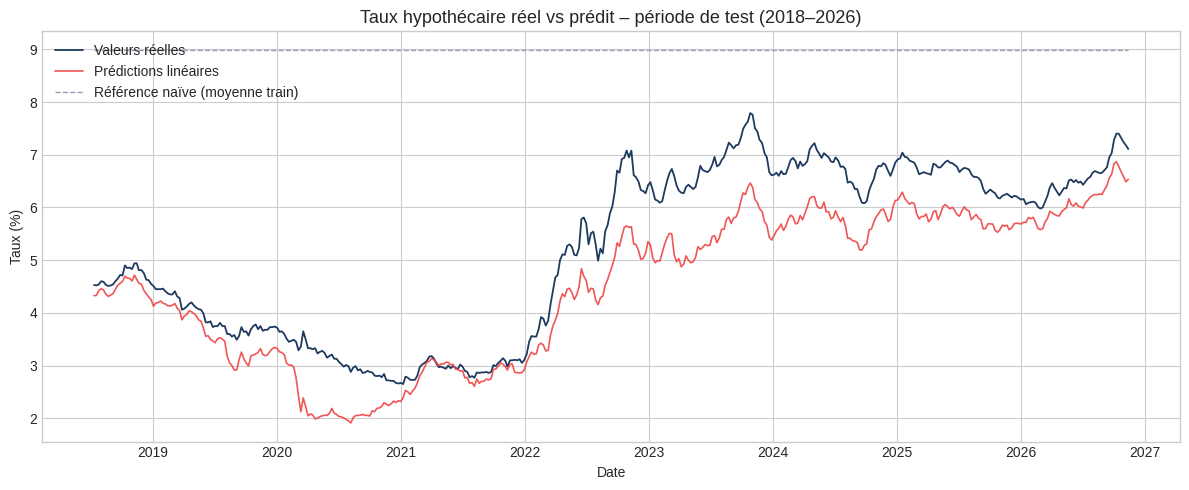

In [40]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test['date'], y_test, label='Valeurs réelles', color='#1e3a5f', linewidth=1.3)
ax.plot(test['date'], y_pred_test, label='Prédictions linéaires', color='#ef4444', linewidth=1.2, alpha=0.9)
ax.plot(test['date'], y_naive_test, label='Référence naïve (moyenne train)', color='#94a3b8', linestyle='--', linewidth=1)
ax.set_title('Taux hypothécaire réel vs prédit – période de test (2018–2026)', fontsize=13)
ax.set_xlabel('Date')
ax.set_ylabel('Taux (%)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(FIGURES / '04_predictions_test.png', dpi=150, bbox_inches='tight')
plt.show()


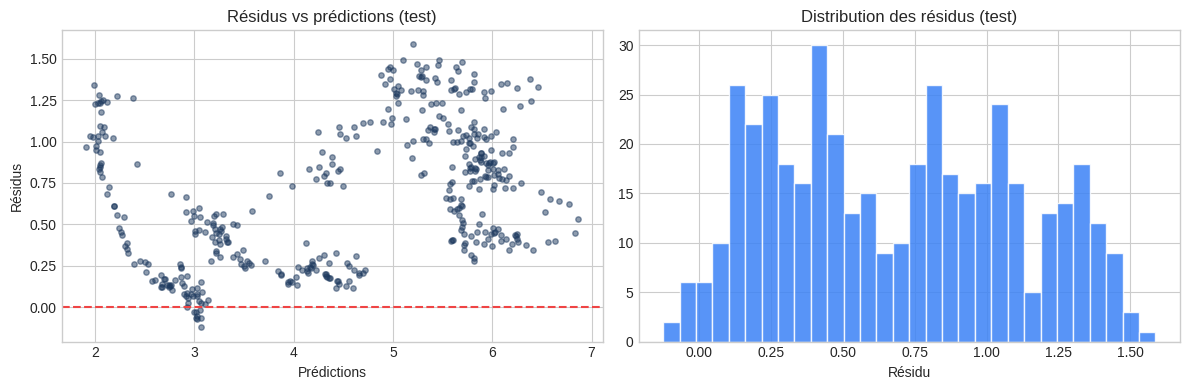

Résidu moyen : 0.6831 | Écart-type des résidus : 0.4199


In [41]:
residus = y_test - y_pred_test
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_test, residus, alpha=0.5, s=15, color='#1e3a5f')
axes[0].axhline(0, color='#ef4444', linestyle='--')
axes[0].set_xlabel('Prédictions')
axes[0].set_ylabel('Résidus')
axes[0].set_title('Résidus vs prédictions (test)')
axes[1].hist(residus, bins=30, color='#3b82f6', edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Résidu')
axes[1].set_title('Distribution des résidus (test)')
plt.tight_layout()
plt.savefig(FIGURES / '05_residus_test.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Résidu moyen : {residus.mean():.4f} | Écart-type des résidus : {residus.std():.4f}')


## 7. Conclusion et réponse à la problématique

### Résultats principaux
- Le modèle de régression linéaire simple **surpasse nettement** la référence naïve (RMSE ≈ 0,80 vs 4,12).
- Le coefficient $\beta_1 \approx 1{,}05$ indique qu’une hausse d’un point du rendement à 10 ans est associée, en moyenne, à une hausse d’environ 1,05 point du taux hypothécaire.
- Le R² de test ≈ 0,75 signifie qu’environ trois quarts de la variance du taux hypothécaire sur 2018–2026 est capturée par le seul taux à 10 ans.

### Interprétation économique
Le lien est fort et économiquement attendu : les banques se refinancent en partie sur les marchés de long terme et répercutent le coût sur les emprunteurs.  
Le spread positif et variable montre toutefois que d’autres facteurs (prime de risque de crédit, marges, liquidité, anticipations, politique monétaire) jouent un rôle important.

### Limites
- Relation supposée linéaire et stable dans le temps (hypothèse contestable après 2020–2022).
- Une seule variable explicative.
- Pas de prise en compte explicite des régimes de politique monétaire ni des chocs de crédit.
- Dégradation du R² entre train (≈ 0,96) et test (≈ 0,75) : signe de changement de régime.

### Pistes d’amélioration
Ajouter des retards du taux à 10 ans, un indicateur de conditions de crédit ou de volatilité, tout en conservant un protocole chronologique strict et une évaluation honnête sur un test indépendant.

**Réponse directe à la problématique :**  
Le rendement des obligations à 10 ans explique et permet de prévoir une part substantielle de l’évolution du taux hypothécaire à 30 ans (R² ≈ 0,75, RMSE nettement inférieur à la naïve). Il ne suffit cependant pas à lui seul : le spread et les conditions de marché restent déterminants.


In [42]:
# Sauvegarde des prédictions et métriques pour cohérence des livrables
out = test[['date', 'Mortgage_30Y', 'Treasury_10Y']].copy()
out['y_pred_lr'] = y_pred_test
out['y_naive'] = y_naive_test
out['residual'] = residus
out.to_csv(DATA / 'test_predictions.csv', index=False)

metrics_save = {
    'beta0': float(beta0),
    'beta1': float(beta1),
    'rmse_naive': float(metrics['Référence naïve']['RMSE']),
    'mae_naive': float(metrics['Référence naïve']['MAE']),
    'r2_naive': float(metrics['Référence naïve']['R²']),
    'rmse_lr': float(metrics['Régression linéaire']['RMSE']),
    'mae_lr': float(metrics['Régression linéaire']['MAE']),
    'r2_lr': float(metrics['Régression linéaire']['R²']),
    'rmse_poly': float(metrics['Régression polynomiale (deg 2)']['RMSE']),
    'mae_poly': float(metrics['Régression polynomiale (deg 2)']['MAE']),
    'r2_poly': float(metrics['Régression polynomiale (deg 2)']['R²']),
    'n_train': len(train),
    'n_val': len(val),
    'n_test': len(test),
    'train_start': str(train['date'].min().date()),
    'train_end': str(train['date'].max().date()),
    'test_start': str(test['date'].min().date()),
    'test_end': str(test['date'].max().date()),
    'corr': float(corr),
    'mean_mortgage_train': float(mean_train)
}
import json
with open(DATA / 'metrics.json', 'w') as f:
    json.dump(metrics_save, f, indent=2)
print('Fichiers de sortie sauvegardés.')
print('Fin du notebook.')


Fichiers de sortie sauvegardés.
Fin du notebook.
